# Figure S1 — Eukaryotic class relative abundance

Standalone script for manuscript code availability. Produces bar charts of
eukaryotic class relative abundance from three data types:

1. Bulk 18S rRNA metagenomics
2. Single-cell RNA-seq (ViHoP taxonomy)
3. Single-cell DNA-seq

No external project modules are required beyond standard Python packages.

In [1]:
from pathlib import Path
from typing import Iterable, Optional, Sequence, Tuple, Union

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
OTHER_LABELS = ("Other eukaryotes", "Other Eukaryotes")

BASE_COLORS = [
    "#0b2e6d",
    "#1d438a",
    "#345da8",
    "#4b587f",
    "#5d5d72",
    "#707070",
    "#8f8f8f",
    "#b1ada1",
    "#c1bc8d",
    "#d2cb56",
    "#e4d83a",
    "#f0df2a",
    "#f7e61b",
    "#f9ea0d",
    "#f6c945",
    "#f2a541",
    "#e76f51",
    "#d1495b",
    "#9c6644",
    "#6d597a",
]


def merge_taxa(
    df: pd.DataFrame,
    groups: Sequence[str],
    megagroup: str,
) -> pd.DataFrame:
    """Sum rows belonging to `groups` into a single `megagroup` row."""
    present = [name for name in groups if name in df.index]
    if present:
        df = df.copy()
        df.loc[megagroup] = df.loc[present].sum(axis=0)
        df = df.drop(index=present)
    return df


def collapse_minor_taxa(
    abundance: pd.Series,
    threshold: float = 1.0,
    other_label: str = "Other eukaryotes",
) -> pd.Series:
    """Keep classes >= threshold (%) and sum the rest into `other_label`."""
    abundance = abundance.sort_values(ascending=False)
    major = abundance[abundance >= threshold]
    minor_total = abundance[abundance < threshold].sum()
    if minor_total > 0:
        major = pd.concat([major, pd.Series({other_label: minor_total})])
    return move_other_to_end(major)


def move_other_to_end(
    abundance: pd.Series,
    other_labels: Sequence[str] = OTHER_LABELS,
) -> pd.Series:
    """Place catch-all 'Other' categories at the right end of the bar chart."""
    present_other = [label for label in other_labels if label in abundance.index]
    if not present_other:
        return abundance
    rest = abundance.drop(present_other)
    other_part = abundance.loc[present_other]
    return pd.concat([rest, other_part])


def bar_colors(n_bars: int) -> list:
    """Return the manuscript color palette; last bar is gray for 'Other'."""
    palette = list(BASE_COLORS)
    while len(palette) < max(n_bars - 1, 0):
        palette.extend(BASE_COLORS)
    return palette[: max(n_bars - 1, 0)] + ["#9E9E9E"]


def format_percent(value: float, decimal_places: int) -> str:
    if decimal_places == 0:
        return f"{round(value):.0f}%"
    return f"{value:.{decimal_places}f}%"


def plot_abundance_bar(
    abundance: pd.Series,
    y_label: str,
    decimal_places: int = 1,
    save_path: Optional[Union[str, Path]] = None,
    show: bool = True,
) -> plt.Figure:
    """Plot relative-abundance bar chart with manuscript styling."""
    abundance = move_other_to_end(abundance)
    colors = bar_colors(len(abundance))

    plt.rcParams["font.family"] = "DejaVu Sans"
    fig, ax = plt.subplots(figsize=(5, 4), dpi=300)

    bars = ax.bar(
        abundance.index,
        abundance.values,
        color=colors,
        edgecolor="none",
        width=0.82,
    )

    for bar, value in zip(bars, abundance.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.3,
            format_percent(value, decimal_places),
            ha="center",
            va="bottom",
            fontsize=6,
        )

    ax.set_ylabel(y_label, fontsize=9, fontweight="bold")
    ax.set_xlabel("Eukaryotic Class", fontsize=9, fontweight="bold")
    ax.set_ylim(0, abundance.max() * 1.1)
    ax.tick_params(axis="x", labelrotation=45, labelsize=6, length=0)
    ax.tick_params(axis="y", labelsize=7)
    for label in ax.get_xticklabels():
        label.set_ha("right")
        label.set_rotation_mode("anchor")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)
    ax.grid(False)

    plt.tight_layout()
    if save_path:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight")
        print(f"Saved {save_path}")
    if show:
        plt.show()
    else:
        plt.close(fig)
    return fig

In [3]:
def load_18s_abundance(path: Union[str, Path]) -> pd.Series:
    """Load and aggregate bulk 18S rRNA relative abundance by eukaryotic class."""
    df = pd.read_csv(path, index_col=0)

    df = merge_taxa(
        df,
        [
            "Other Metazoa", "Annelida", "Arthropoda", "Cnidaria", "Craniata",
            "Ctenophora", "Gastrotricha", "Metazoa_X", "Mollusca", "Nematoda",
            "Platyhelminthes", "Porifera", "Rotifera",
        ],
        "Metazoa",
    )
    df = merge_taxa(
        df,
        ["Bacillariophyceae", "Coscinodiscophyceae", "Mediophyceae", "Diatomeae_X"],
        "Diatoms",
    )
    df = merge_taxa(
        df,
        ["Dinophyta_X", "Unclassified Dinoflagellata", "Noctilucophyceae", "Syndiniales"],
        "Other Dinoflagellata",
    )
    df = merge_taxa(
        df,
        ["Haptophyta_XX", "Prymnesiophyceae", "Pavlovophyceae"],
        "Haptophytes",
    )

    total_reads = df.sum(axis=1)
    abundance = total_reads / total_reads.sum() * 100
    return collapse_minor_taxa(abundance)


def load_scrna_abundance(path: Union[str, Path]) -> pd.Series:
    """Load scRNA-seq class abundance from homogeneous ViHoP cell assignments."""
    df = pd.read_csv(path)
    homogeneous = df[df["percent"] == 1.0]
    abundance = (
        homogeneous["Class"]
        .value_counts(normalize=True)
        .mul(100)
        .sort_values(ascending=False)
    )
    abundance = collapse_minor_taxa(abundance)
    return abundance.round(0)


def load_scdna_abundance(path: Union[str, Path]) -> pd.Series:
    """Load precomputed scDNA-seq class-level relative abundances."""
    df = pd.read_csv(path, sep="\t", index_col=0)
    abundance = df["percentage"].sort_values(ascending=False).round(0)
    return move_other_to_end(abundance)

In [4]:
# --- configuration ---
base_path = Path("/home/labs/vardi/amirz/pairing/Alps_All_MetaG")
output_dir = base_path / "gene_expression" / "figure_s1_abundance"

paths = {
    "18s": base_path
    / "18S_analysis_GKS/Metagenomes_2024_sc_sampling/Metagenome_abundance.csv",
    "scrna": base_path / "ViHoP/blast_summary.Class.csv",
    "scdna": base_path / "scDNA/Relative_abundances_SPCs_class_level.tab",
}

outputs = {
    "18s": output_dir / "figure_s1_abundance_18S.png",
    "scrna": output_dir / "figure_s1_abundance_scRNA.png",
    "scdna": output_dir / "figure_s1_abundance_scDNA.png",
}

### Bulk 18S rRNA metagenomics

Dinophyceae                46.192389
Chrysophyceae              11.469396
Haptophytes                 8.421758
Diatoms                     7.224839
Unidentified Eukaryotes     4.466074
dtype: float64
Saved /home/labs/vardi/amirz/pairing/Alps_All_MetaG/gene_expression/figure_s1_abundance/figure_s1_abundance_18S.png


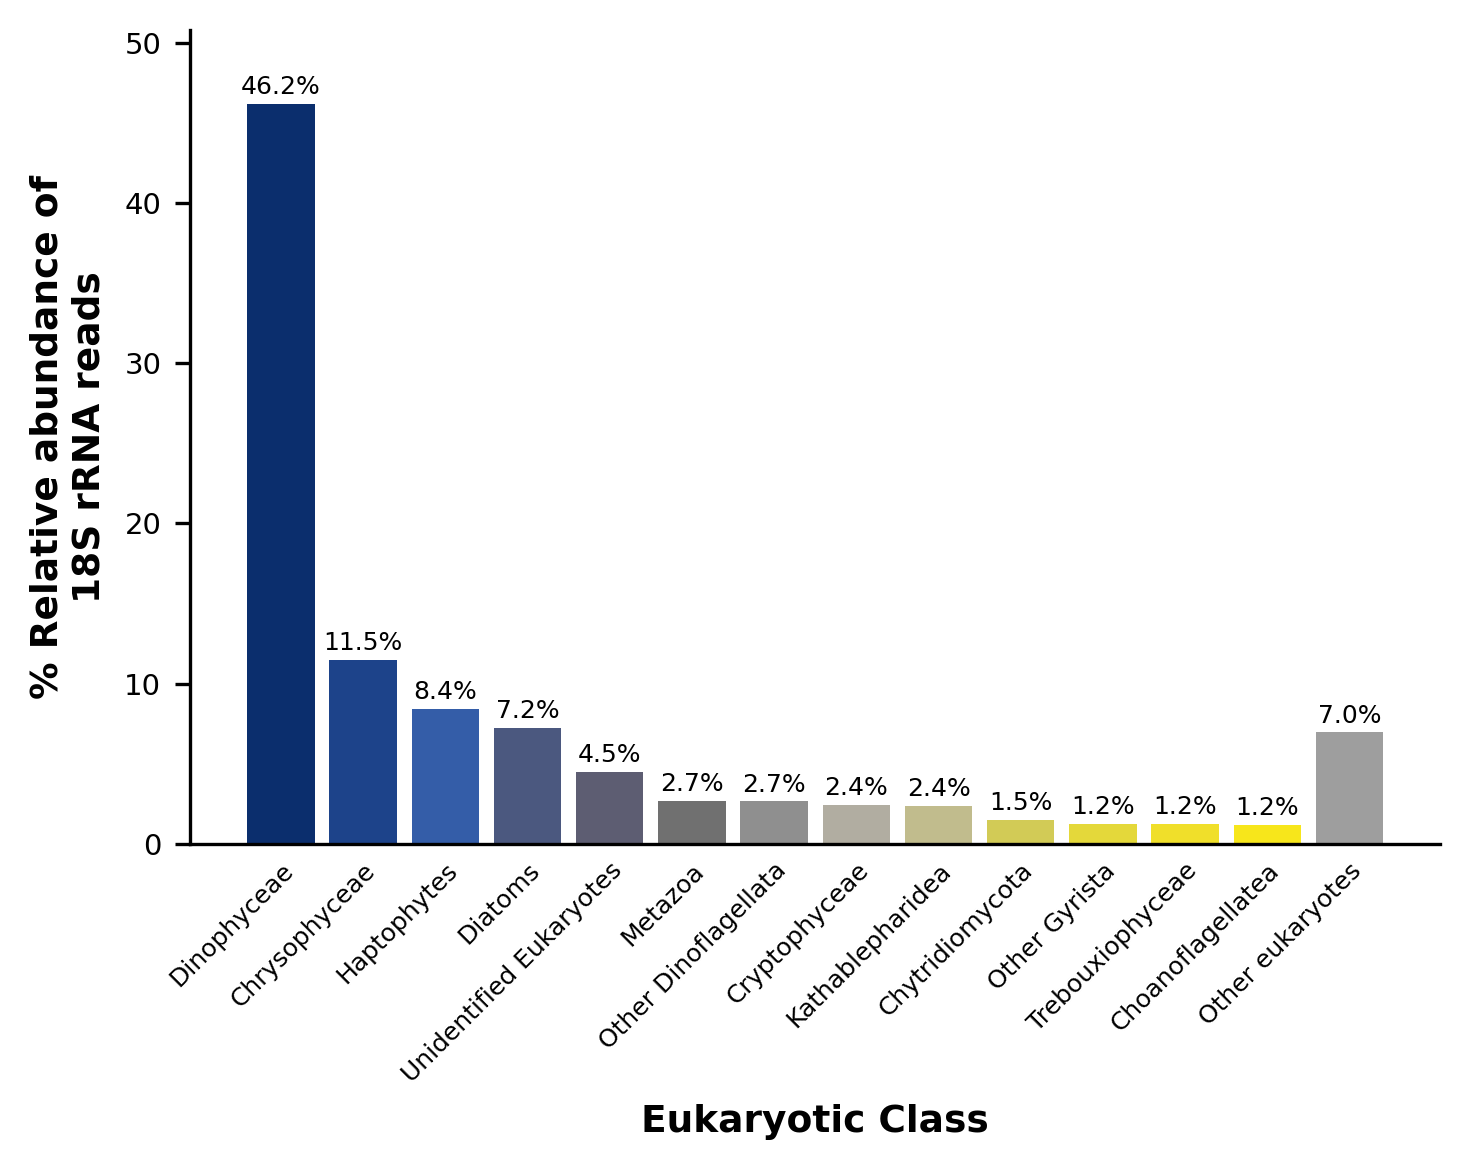

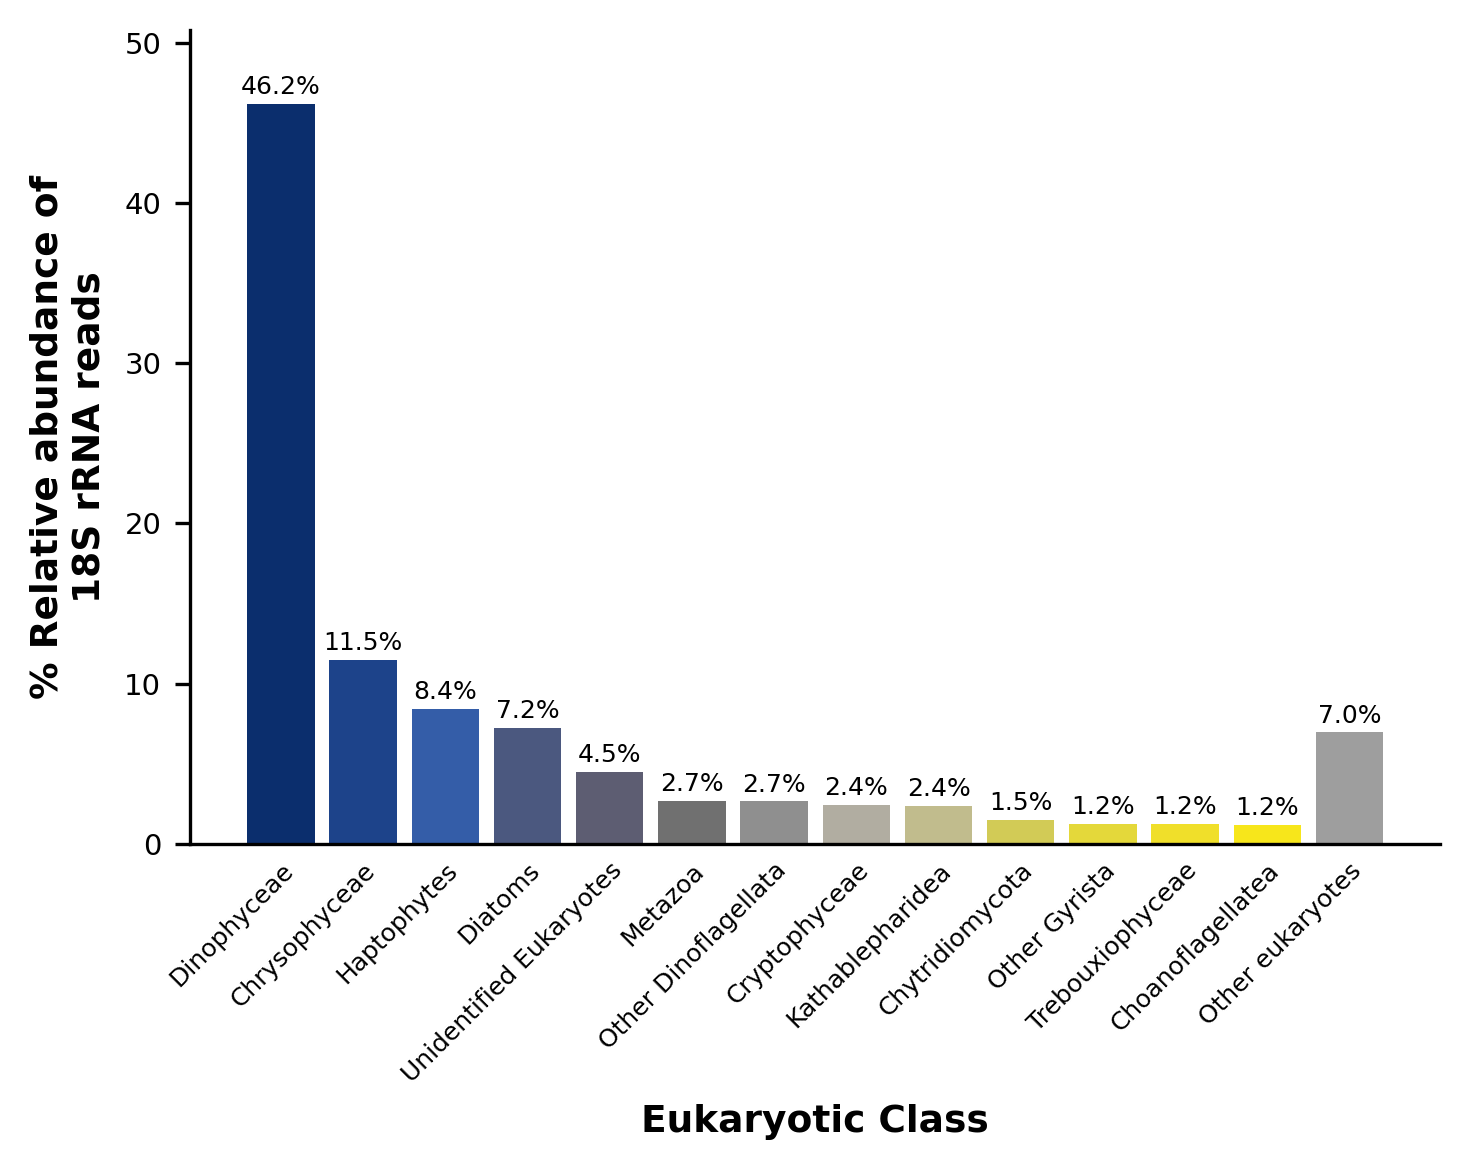

In [5]:
abundance_18s = load_18s_abundance(paths["18s"])
print(abundance_18s.head())
plot_abundance_bar(
    abundance_18s,
    y_label="% Relative abundance of\n18S rRNA reads",
    decimal_places=1,
    save_path=outputs["18s"],
)

### Single-cell RNA-seq

Chrysophyceae        41.0
Chlorophyceae        18.0
Dinophyceae          12.0
Bacillariophyceae     9.0
Zygnemophyceae        5.0
dtype: float64
Saved /home/labs/vardi/amirz/pairing/Alps_All_MetaG/gene_expression/figure_s1_abundance/figure_s1_abundance_scRNA.png


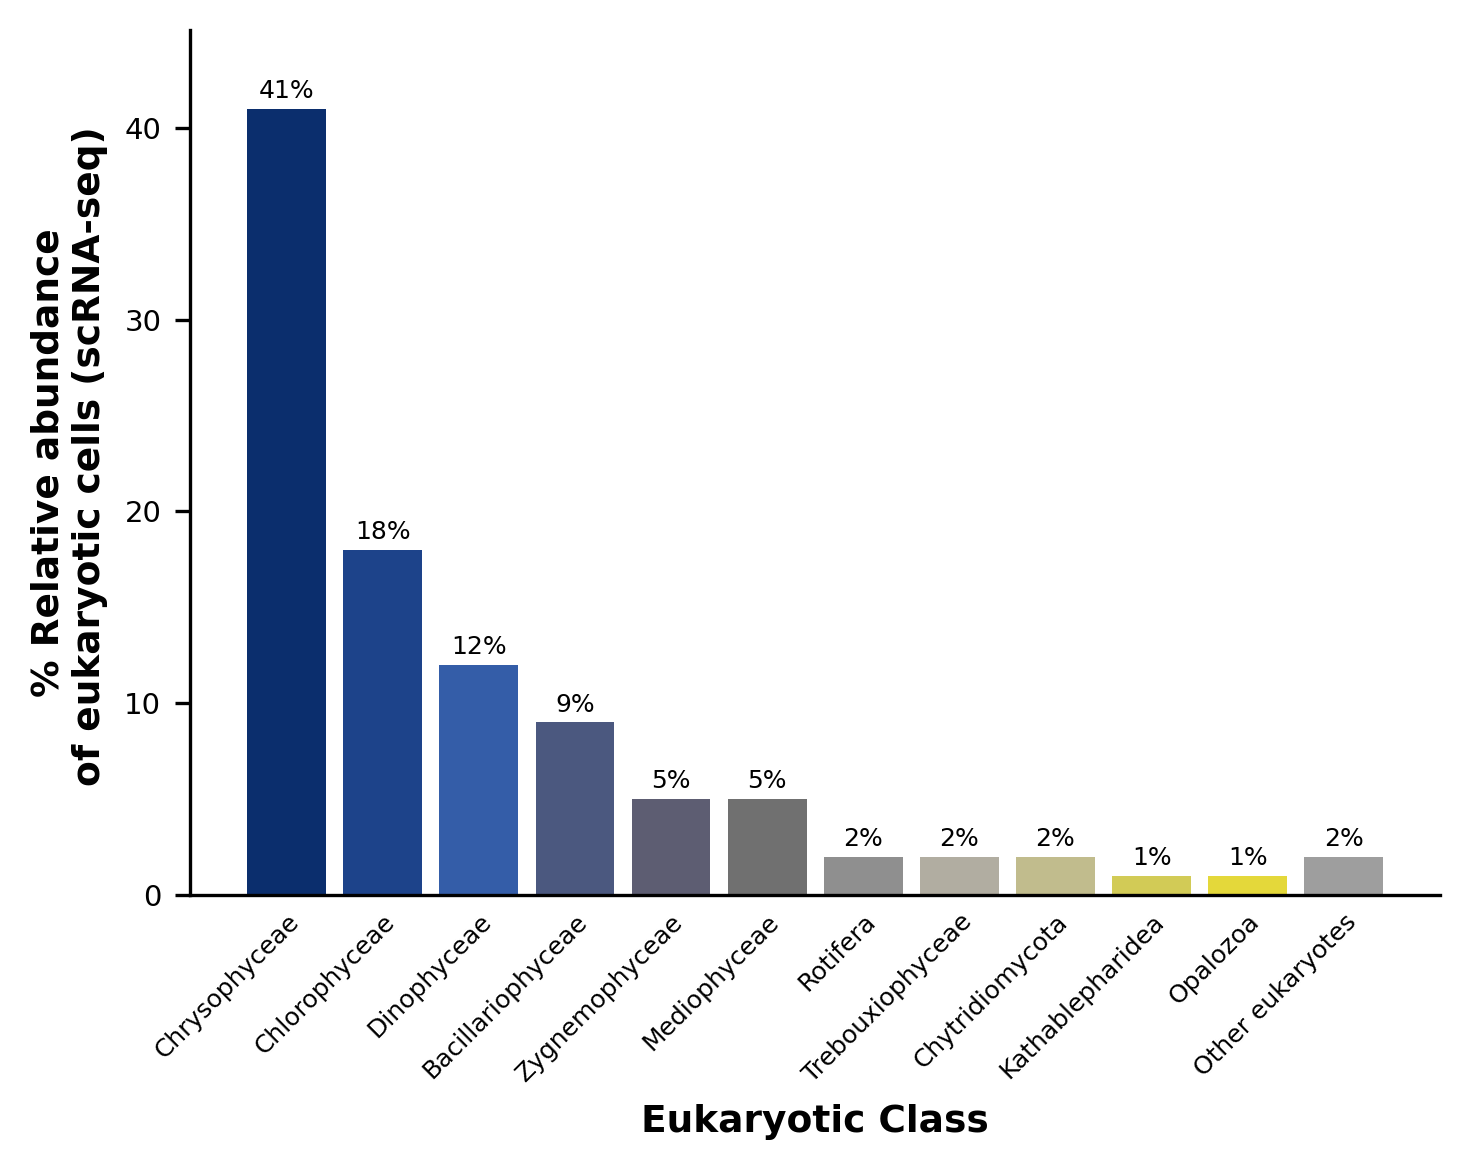

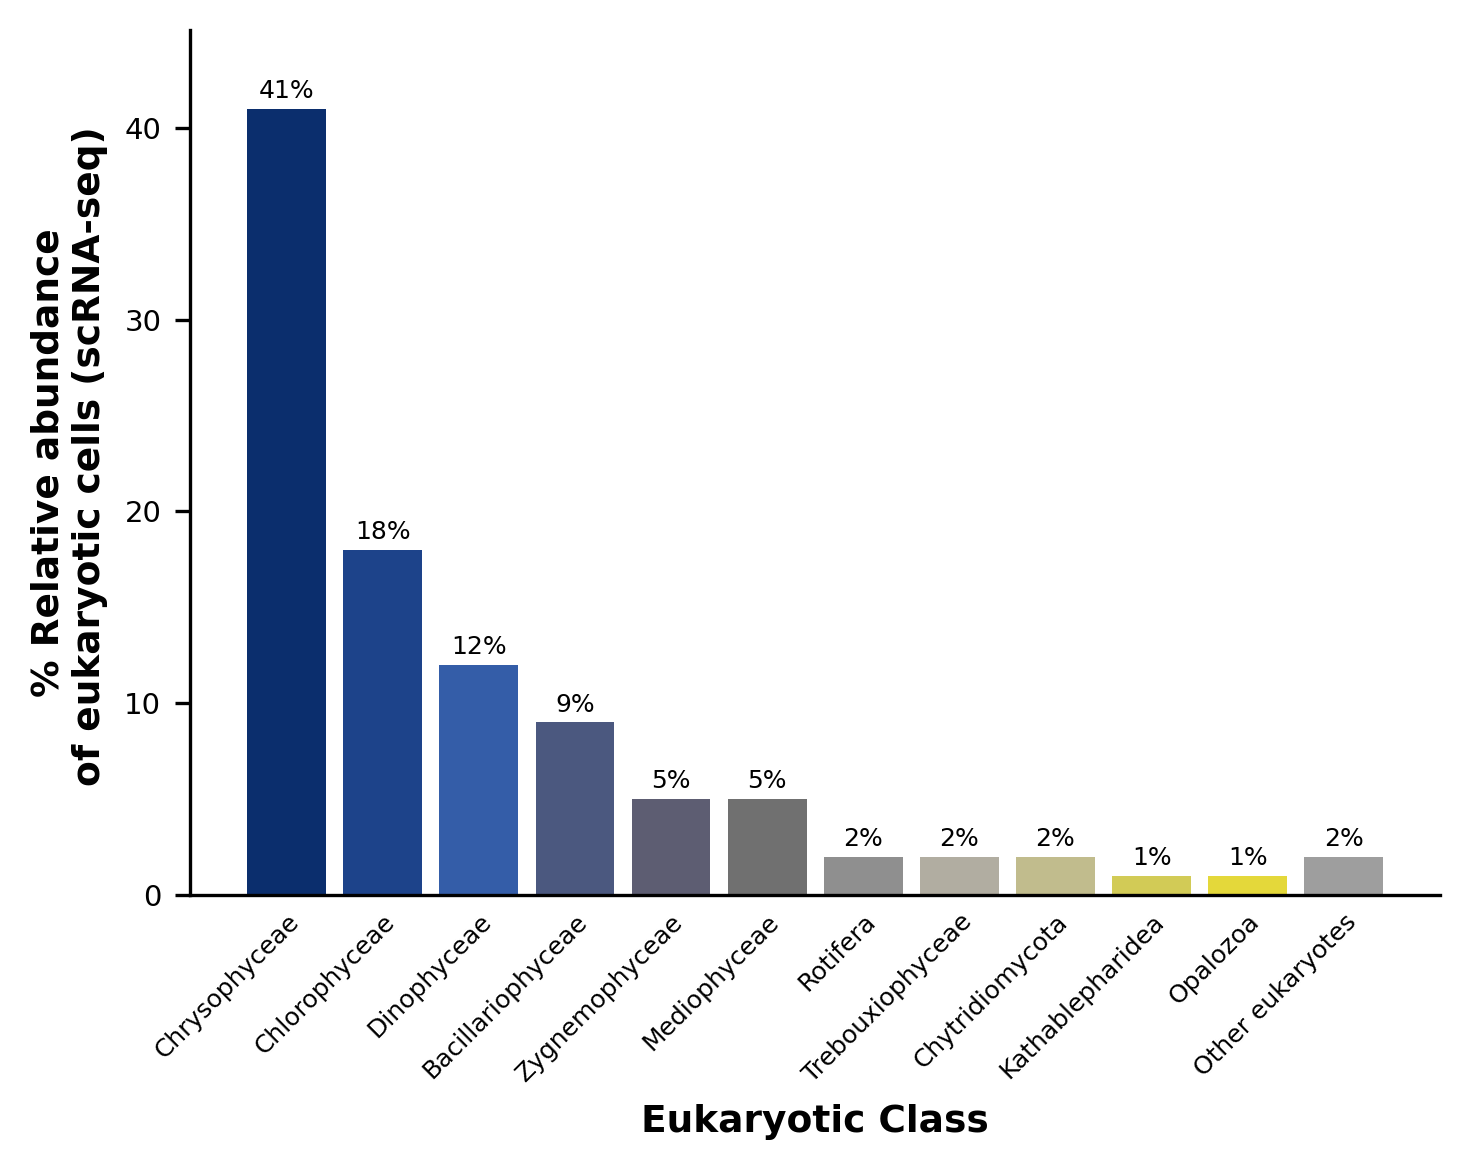

In [6]:
abundance_scrna = load_scrna_abundance(paths["scrna"])
print(abundance_scrna.head())
plot_abundance_bar(
    abundance_scrna,
    y_label="% Relative abundance\n of eukaryotic cells (scRNA-seq)",
    decimal_places=0,
    save_path=outputs["scrna"],
)

### Single-cell DNA-seq

class
Chrysophyceae        43.0
Eumycetozoa          10.0
Bacillariophyceae     7.0
Synurophyceae         4.0
Filasterea            4.0
Name: percentage, dtype: float64
Saved /home/labs/vardi/amirz/pairing/Alps_All_MetaG/gene_expression/figure_s1_abundance/figure_s1_abundance_scDNA.png


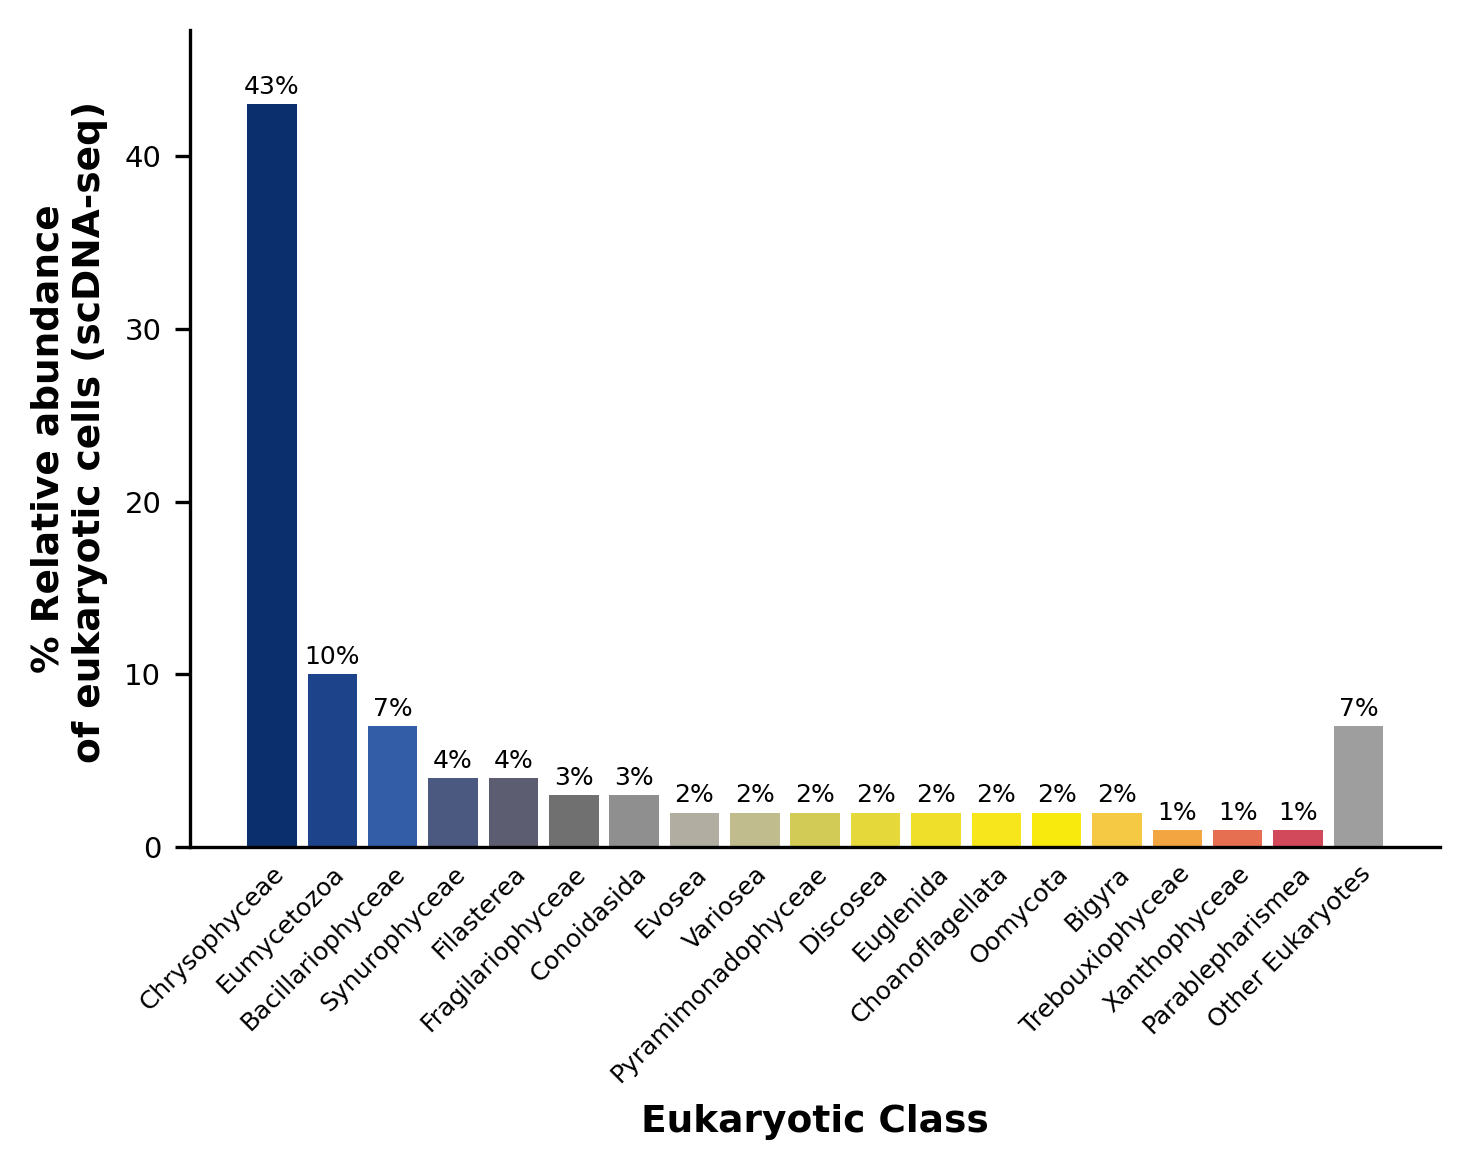

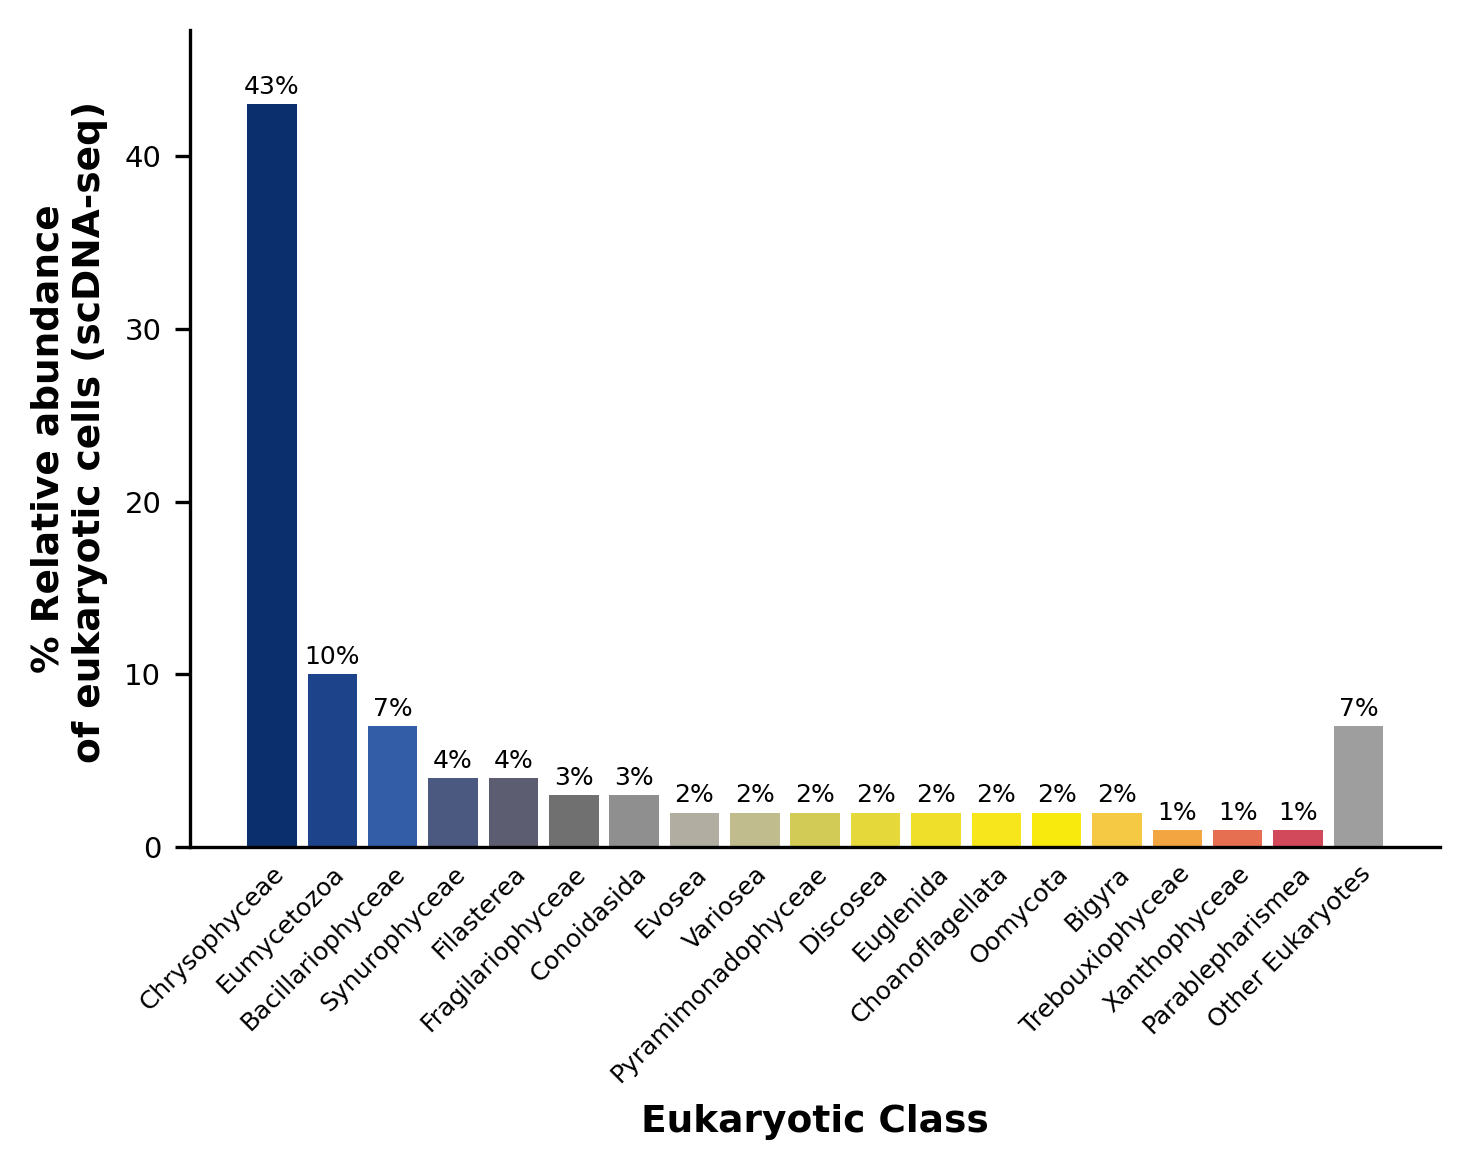

In [7]:
abundance_scdna = load_scdna_abundance(paths["scdna"])
print(abundance_scdna.head())
plot_abundance_bar(
    abundance_scdna,
    y_label="% Relative abundance\n of eukaryotic cells (scDNA-seq)",
    decimal_places=0,
    save_path=outputs["scdna"],
)